In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

In [2]:
data_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(data_path):
    data_path = os.path.join("30-10-2026", "Task 2", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(data_path)
df['Full_Review_Text'] = df['Full_Review_Text'].fillna('')

pos_mask = df['Recommended IND'] == 1
neg_mask = df['Recommended IND'] == 0

pos_texts = df.loc[pos_mask, 'Full_Review_Text'].tolist()
neg_texts = df.loc[neg_mask, 'Full_Review_Text'].tolist()
print(f"Loaded {len(pos_texts)} Positive and {len(neg_texts)} Negative customer reviews.")

Loaded 19314 Positive and 4172 Negative customer reviews.


In [3]:
ngrams_csv = "sentiment_specific_ngrams_summary.csv"
if not os.path.exists(ngrams_csv):
    ngrams_csv = os.path.join("30-10-2026", "Task 2", "sentiment_specific_ngrams_summary.csv")

df_ngrams_all = pd.read_csv(ngrams_csv)
display(df_ngrams_all.head(12))

,Ngram,Frequency,Sentiment,Relative_Pct,Ngram_Type
0,but not,1166,Positive,6.04,Bigram
1,very flattering,893,Positive,4.62,Bigram
2,not too,867,Positive,4.49,Bigram
3,love love,699,Positive,3.62,Bigram
4,up or,697,Positive,3.61,Bigram
5,love top,605,Positive,3.13,Bigram
6,or down,601,Positive,3.11,Bigram
7,well made,581,Positive,3.01,Bigram
8,very comfortable,567,Positive,2.94,Bigram
9,fit perfectly,552,Positive,2.86,Bigram


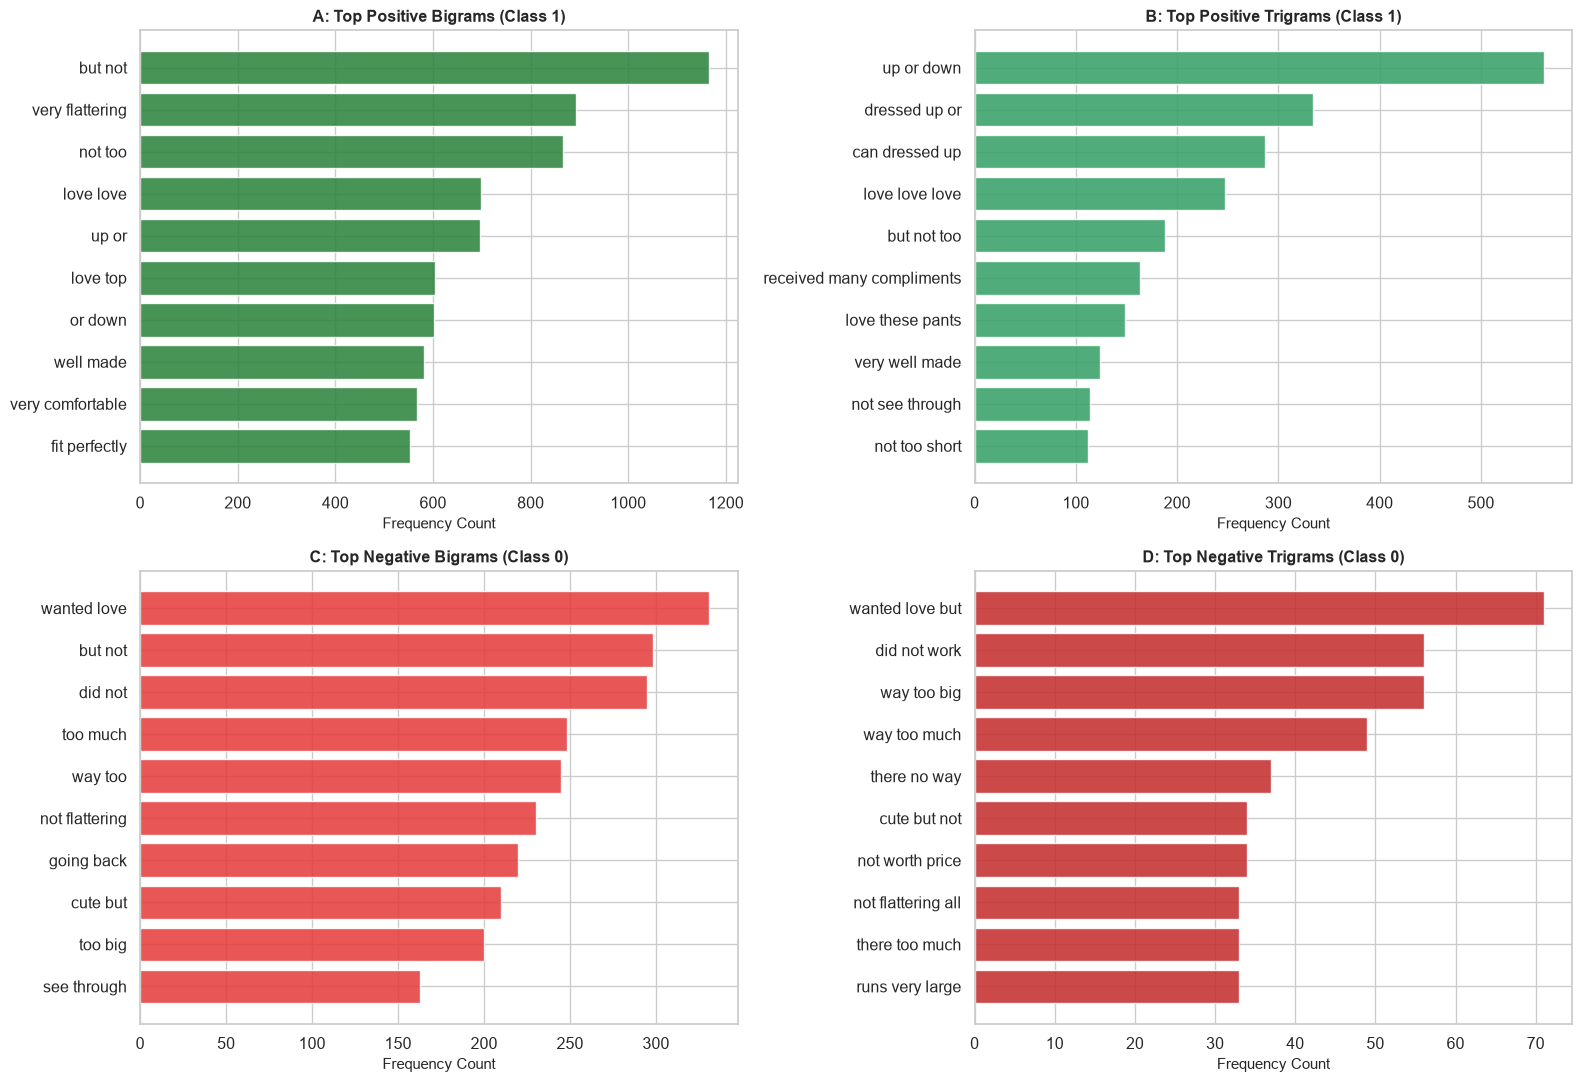

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

df_pos_b = df_ngrams_all[(df_ngrams_all['Sentiment'] == 'Positive') & (df_ngrams_all['Ngram_Type'] == 'Bigram')].head(10)
df_pos_t = df_ngrams_all[(df_ngrams_all['Sentiment'] == 'Positive') & (df_ngrams_all['Ngram_Type'] == 'Trigram')].head(10)
df_neg_b = df_ngrams_all[(df_ngrams_all['Sentiment'] == 'Negative') & (df_ngrams_all['Ngram_Type'] == 'Bigram')].head(10)
df_neg_t = df_ngrams_all[(df_ngrams_all['Sentiment'] == 'Negative') & (df_ngrams_all['Ngram_Type'] == 'Trigram')].head(10)

axes[0, 0].barh(df_pos_b['Ngram'][::-1], df_pos_b['Frequency'][::-1], color='#2E8540', alpha=0.88)
axes[0, 0].set_title("A: Top Positive Bigrams (Class 1)", fontsize=11.5, fontweight='bold')
axes[0, 0].set_xlabel("Frequency Count", fontsize=10.5)

axes[0, 1].barh(df_pos_t['Ngram'][::-1], df_pos_t['Frequency'][::-1], color='#38A169', alpha=0.88)
axes[0, 1].set_title("B: Top Positive Trigrams (Class 1)", fontsize=11.5, fontweight='bold')
axes[0, 1].set_xlabel("Frequency Count", fontsize=10.5)

axes[1, 0].barh(df_neg_b['Ngram'][::-1], df_neg_b['Frequency'][::-1], color='#E53E3E', alpha=0.88)
axes[1, 0].set_title("C: Top Negative Bigrams (Class 0)", fontsize=11.5, fontweight='bold')
axes[1, 0].set_xlabel("Frequency Count", fontsize=10.5)

axes[1, 1].barh(df_neg_t['Ngram'][::-1], df_neg_t['Frequency'][::-1], color='#C53030', alpha=0.88)
axes[1, 1].set_title("D: Top Negative Trigrams (Class 0)", fontsize=11.5, fontweight='bold')
axes[1, 1].set_xlabel("Frequency Count", fontsize=10.5)

plt.tight_layout()
plt.show()

In [5]:
cooccur_csv = "word_cooccurrence_top_pairs.csv"
if not os.path.exists(cooccur_csv):
    cooccur_csv = os.path.join("30-10-2026", "Task 2", "word_cooccurrence_top_pairs.csv")

df_pairs = pd.read_csv(cooccur_csv)
display(df_pairs.head(10))

,Word_1,Word_2,Positive_Cooccurrences,Negative_Cooccurrences,Positive_Rate,Negative_Rate
0,love,great,2999,145,155.28,34.76
1,love,perfect,1611,52,83.41,12.46
2,love,small,1165,167,60.32,40.03
3,soft,love,1148,63,59.44,15.10
4,love,beautiful,1085,130,56.18,31.16
5,perfect,great,930,41,48.15,9.83
6,flattering,love,888,84,45.98,20.13
7,comfortable,love,874,32,45.25,7.67
8,great,small,809,89,41.89,21.33
9,soft,great,733,38,37.95,9.11


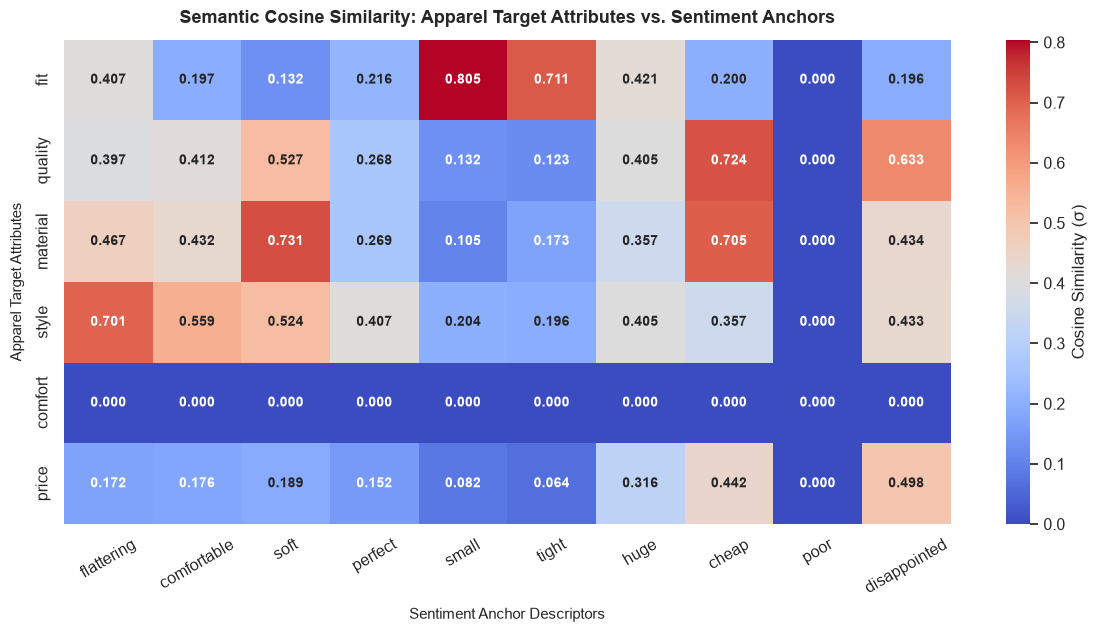

In [6]:
sim_csv = "glove_word2vec_attribute_similarities.csv"
if not os.path.exists(sim_csv):
    sim_csv = os.path.join("30-10-2026", "Task 2", "glove_word2vec_attribute_similarities.csv")

df_sim = pd.read_csv(sim_csv, index_col=0)
fig, ax = plt.subplots(figsize=(12, 6.5))
sns.heatmap(df_sim, annot=True, fmt='.3f', cmap='coolwarm', ax=ax, cbar_kws={'label': 'Cosine Similarity (\u03c3)'}, annot_kws={'size': 10, 'weight': 'bold'})
ax.set_title("Semantic Cosine Similarity: Apparel Target Attributes vs. Sentiment Anchors", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Sentiment Anchor Descriptors", fontsize=11, labelpad=8)
ax.set_ylabel("Apparel Target Attributes", fontsize=11, labelpad=8)
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

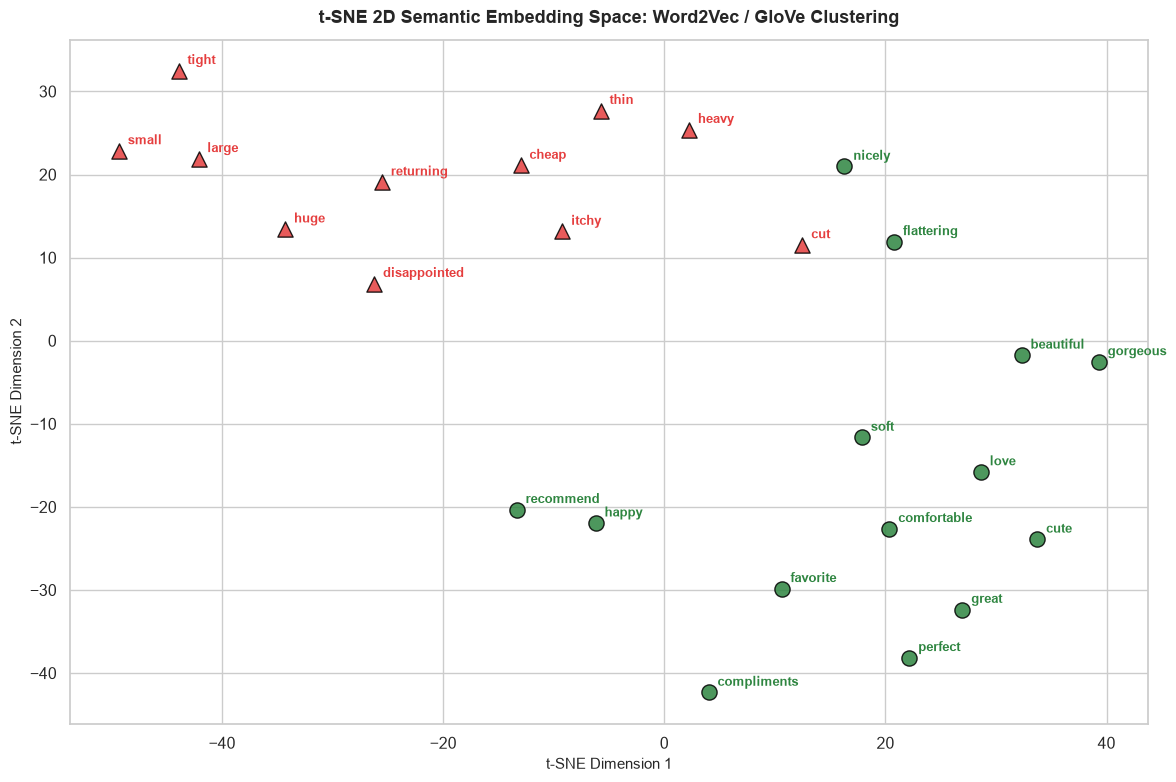

In [7]:
proj_csv = "word_embedding_projections_2d.csv"
if not os.path.exists(proj_csv):
    proj_csv = os.path.join("30-10-2026", "Task 2", "word_embedding_projections_2d.csv")

df_proj = pd.read_csv(proj_csv)
fig, ax = plt.subplots(figsize=(12, 8))

for idx, r in df_proj.iterrows():
    c = '#2E8540' if r['Sentiment_Polarity'] == 'Positive' else '#E53E3E'
    m = 'o' if r['Sentiment_Polarity'] == 'Positive' else '^'
    ax.scatter(r['Dimension_1'], r['Dimension_2'], color=c, marker=m, s=120, alpha=0.85, edgecolors='black')
    ax.annotate(r['Word'], (r['Dimension_1'] + 0.8, r['Dimension_2'] + 0.8), fontsize=9.5, fontweight='bold', color=c)

ax.set_title("t-SNE 2D Semantic Embedding Space: Word2Vec / GloVe Clustering", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("t-SNE Dimension 1", fontsize=11)
ax.set_ylabel("t-SNE Dimension 2", fontsize=11)
plt.tight_layout()
plt.show()